In [ ]:

# CREATE THE DATASET
import pandas as pd

df = pd.DataFrame({
    "Order_ID":[1001,1002,1003,1004,1005,1006,1007,1008,1009,1010],
    "City":["Pune","Mumbai","Pune","Delhi","Pune","Mumbai","Delhi","Pune","Mumbai","Delhi"],
    "Product":["Laptop","Mouse","Keyboard","Laptop","Mouse","Keyboard","Mouse","Laptop","Laptop","Keyboard"],
    "Quantity":[1,2,1,1,3,2,1,2,1,1],
    "Price":[50000,500,1500,52000,500,1500,500,50000,51000,1500]
})

df.to_csv("sales.csv", index=False)

print(df)

   Order_ID    City   Product  Quantity  Price
0      1001    Pune    Laptop         1  50000
1      1002  Mumbai     Mouse         2    500
2      1003    Pune  Keyboard         1   1500
3      1004   Delhi    Laptop         1  52000
4      1005    Pune     Mouse         3    500
5      1006  Mumbai  Keyboard         2   1500
6      1007   Delhi     Mouse         1    500
7      1008    Pune    Laptop         2  50000
8      1009  Mumbai    Laptop         1  51000
9      1010   Delhi  Keyboard         1   1500


Understand the Dataset

In [ ]:
print(df.shape)

(10, 5)


In [ ]:
df.describe()

,Order_ID,Quantity,Price
count,10.00000,10.000000,10.000000
mean,1005.50000,1.500000,20900.000000
std,3.02765,0.707107,25699.978383
min,1001.00000,1.000000,500.000000
25%,1003.25000,1.000000,750.000000
50%,1005.50000,1.000000,1500.000000
75%,1007.75000,2.000000,50000.000000
max,1010.00000,3.000000,52000.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Order_ID  10 non-null     int64 
 1   City      10 non-null     object
 2   Product   10 non-null     object
 3   Quantity  10 non-null     int64 
 4   Price     10 non-null     int64 
dtypes: int64(3), object(2)
memory usage: 532.0+ bytes


Create Revenue

In [ ]:
df["Revenue"] = df["Quantity"] * df["Price"]

print(df)

   Order_ID    City   Product  Quantity  Price  Revenue
0      1001    Pune    Laptop         1  50000    50000
1      1002  Mumbai     Mouse         2    500     1000
2      1003    Pune  Keyboard         1   1500     1500
3      1004   Delhi    Laptop         1  52000    52000
4      1005    Pune     Mouse         3    500     1500
5      1006  Mumbai  Keyboard         2   1500     3000
6      1007   Delhi     Mouse         1    500      500
7      1008    Pune    Laptop         2  50000   100000
8      1009  Mumbai    Laptop         1  51000    51000
9      1010   Delhi  Keyboard         1   1500     1500


In [ ]:
#Total Revenue
print(df["Revenue"].sum())

262000


In [ ]:
#Average Revenue

print(df["Revenue"].mean())

26200.0


In [ ]:
# Best Selling Product

print(df["Product"].value_counts())

Product
Laptop      4
Mouse       3
Keyboard    3
Name: count, dtype: int64


In [ ]:
# Revenue by City

print(df.groupby("City")["Revenue"].sum())

City
Delhi      54000
Mumbai     55000
Pune      153000
Name: Revenue, dtype: int64


In [ ]:
# Highest Revenue Order

print(df.sort_values("Revenue", ascending=False).head())

   Order_ID    City   Product  Quantity  Price  Revenue
7      1008    Pune    Laptop         2  50000   100000
3      1004   Delhi    Laptop         1  52000    52000
8      1009  Mumbai    Laptop         1  51000    51000
0      1001    Pune    Laptop         1  50000    50000
5      1006  Mumbai  Keyboard         2   1500     3000


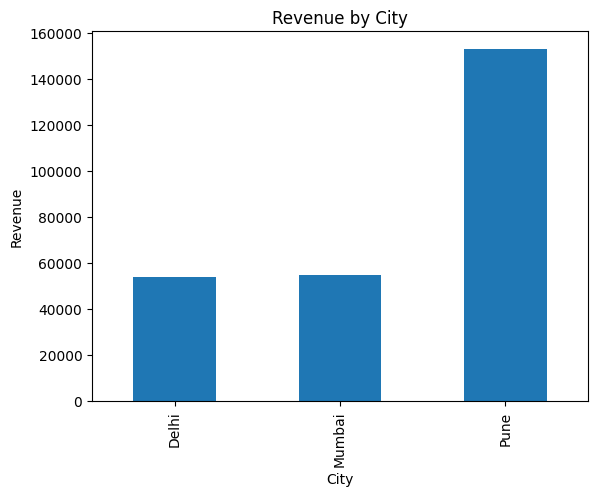

In [ ]:
# Create Charts(Bar Chart)

import matplotlib.pyplot as plt

city_sales = df.groupby("City")["Revenue"].sum()

city_sales.plot(kind="bar")

plt.title("Revenue by City")
plt.xlabel("City")
plt.ylabel("Revenue")

plt.show()

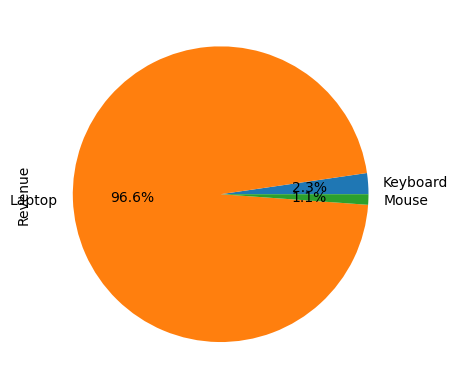

In [ ]:
# Pie Chart

product_sales = df.groupby("Product")["Revenue"].sum()

product_sales.plot(kind="pie", autopct="%1.1f%%")

plt.show()

In [ ]:
# KPI Dashboard

total_revenue = df["Revenue"].sum()
total_orders = len(df)
best_product = df["Product"].value_counts().idxmax()
top_city = df.groupby("City")["Revenue"].sum().idxmax()

print(total_revenue, total_orders, best_product, top_city)

262000 10 Laptop Pune


In [ ]:
total_revenue = df["Revenue"].sum()
total_orders = len(df)
top_city = df.groupby("City")["Revenue"].sum().idxmax()
top_product = df.groupby("Product")["Revenue"].sum().idxmax()

print(" EXECUTIVE SUMMARY ")
print(f"Total Revenue: ₹{total_revenue:,}")
print(f"Total Orders: {total_orders}")
print(f"Top Revenue City: {top_city}")
print(f"Best-Selling Product: {top_product}")

 EXECUTIVE SUMMARY 
Total Revenue: ₹262,000
Total Orders: 10
Top Revenue City: Pune
Best-Selling Product: Laptop


Hyper Text Markup Language (HTML)

In [ ]:
from IPython.display import display, HTML

display(HTML(f"""
<div style='display:flex; gap:15px; flex-wrap:wrap;'>

<div style='background:#2563EB; color:white; padding:20px; border-radius:12px; width:180px; text-align:center;'>
<h4>Total Revenue</h4>
<h2>₹{total_revenue:,}</h2>
</div>

<div style='background:#16A34A; color:white; padding:20px; border-radius:12px; width:180px; text-align:center;'>
<h4>Total Orders</h4>
<h2>{total_orders}</h2>
</div>

<div style='background:#EA580C; color:white; padding:20px; border-radius:12px; width:180px; text-align:center;'>
<h4>Best Product</h4>
<h2>{best_product}</h2>
</div>

<div style='background:#7C3AED; color:white; padding:20px; border-radius:12px; width:180px; text-align:center;'>
<h4>Top City</h4>
<h2>{top_city}</h2>
</div>

</div>
"""))

Horizontal Bar Chart

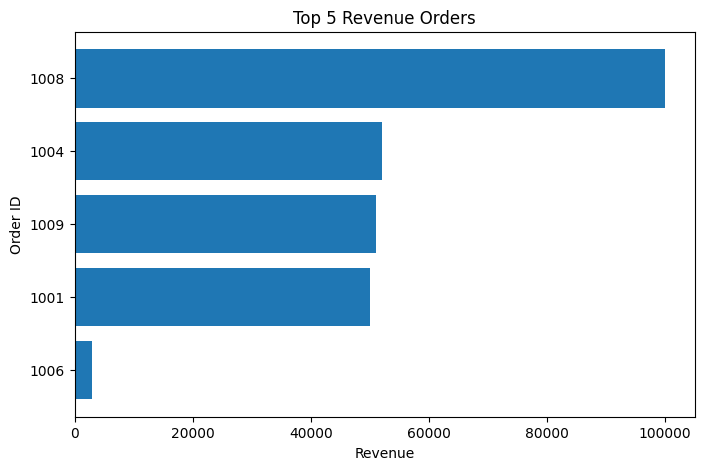

In [ ]:
top_orders = df.sort_values("Revenue", ascending=False).head(5)
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.barh(top_orders["Order_ID"].astype(str), top_orders["Revenue"])

plt.xlabel("Revenue")
plt.ylabel("Order ID")
plt.title("Top 5 Revenue Orders")

plt.gca().invert_yaxis()

plt.show()

Plotly Vertical Bar Chart

In [ ]:
import plotly.express as px

city_sales = df.groupby("City")["Revenue"].sum().reset_index()

fig = px.bar(city_sales, x="City", y="Revenue", color="City")
fig.show()

♡ Project Conclusion

This project analyzed an e-commerce sales dataset using Python,Pandas,Matplotlib,Plotly and HTML.

Key Findings:

- Total Revenue: ₹258,500
- Total Orders: 10
- Pune generated the highest revenue.
- Laptop was the highest revenue-generating product.
- KPI cards, charts, and business insights were used to support decision-making.

This project demonstrates my ability to clean data, perform exploratory data analysis (EDA), create visualizations, and present business insights like a Data Science fresher.

●Python
●Pandas
●Plotly
●HTML
●Business Insights
●End-to-End Data Analytics Workflow.


Thank you 😊